# Lifecycle Analysis: First Pass

Project: **From Hype to Sustainability: Lifecycle Patterns of AI-Related GitHub Repositories** (CS5488)

Scope of this notebook (stage 1): load the cleaned sample data, check its structure, produce basic
statistics and first charts, and prepare the metric definitions and the join with repository metadata
that the later monthly lifecycle analysis will use.

## Data sources used

| Source | Level | Rows (measured) | What it covers |
|---|---|---|---|
| `events_clean.parquet/` | one row = one event | 197,313 | 2024-01-15 UTC 00:00-01:00 (single hour) |
| `repo_daily_counts.csv` (24h) | repo x date x event type | 1,340,785 | 2024-01-15 full day, 5,528,300 events, 852,777 repos |
| `repo_candidates.csv` | one row = one repo | 69,768 | repos seen in the single-hour sample |
| `repo_metadata.csv` (B pilot) | one row = one repo | 50 | API metadata incl. `repo_created_at` |
| `repo_ai_labels_analysis.csv` (B pilot) | one row = one repo | 50 | AI labels and label source |

## Known limits

- The event-level table covers one hour only, so it is used for field checks and event-type counts, not for lifecycle trends.
- Repository metadata and AI labels currently exist for 50 pilot repositories only. Creation time for the whole
  candidate list is still pending from B.
- The 24h daily table holds a single date, so `active_days` is 1 for every repository and cannot support lifecycle
  conclusions yet. It becomes meaningful once the observation window is extended.
- `repo_name` in the event table may be a historical name. Always join on `repo_id`, never on the name.
- Metadata is a 2026-11-02 snapshot, not the repository state on 2024-01-15.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up until the folder that contains a_data_pipeline and b_repo_metadata."""
    for path in [start, *start.parents]:
        if (path / "a_data_pipeline").is_dir() and (path / "b_repo_metadata").is_dir():
            return path
    raise FileNotFoundError("Project root not found. Run the notebook inside the repo.")


ROOT = find_project_root()
A = ROOT / "a_data_pipeline"
B = ROOT / "b_repo_metadata"

# 1-hour event-level table (one row per event)
EVENTS_1H = A / "runs/20240115_1hour_handoff/python/events_clean.parquet"
# repository candidate list
REPO_CANDIDATES = A / "runs/20240115_1hour_handoff/python/repo_candidates.csv"
# aggregated activity counts (repo x date x event type)
DAILY_1H = A / "runs/20240115_1hour_handoff/python/repo_daily_counts.csv"
DAILY_24H = A / "sample_data/20240115_24h/repo_daily_counts.csv"
# B pilot outputs (50 repositories only)
REPO_METADATA = B / "runs/pilot_01/repo_metadata.csv"
REPO_LABELS = B / "runs/pilot_01/repo_ai_labels_analysis.csv"

FIG_DIR = ROOT / "c_lifecycle_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for name, path in [
    ("events_1h", EVENTS_1H), ("candidates", REPO_CANDIDATES),
    ("daily_1h", DAILY_1H), ("daily_24h", DAILY_24H),
    ("metadata", REPO_METADATA), ("labels", REPO_LABELS),
]:
    print(f"{name:12s} exists={path.exists()}  {path}")

events_1h    exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\events_clean.parquet
candidates   exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\repo_candidates.csv
daily_1h     exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\repo_daily_counts.csv
daily_24h    exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\a_data_pipeline\sample_data\20240115_24h\repo_daily_counts.csv
metadata     exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\b_repo_metadata\runs\pilot_01\repo_metadata.csv
labels       exists=True  E:\A_2026CityU\C5488\group work\1109\github_activity_analyze_project\b_repo_metadata\runs\pilot_01\repo_ai_labels_analysis.csv


## 1. Load the data

In [2]:
events_1h = pd.read_parquet(EVENTS_1H)                 # one row = one event
daily_24h = pd.read_csv(DAILY_24H)                     # repo x date x event type
candidates = pd.read_csv(REPO_CANDIDATES)              # one row = one repo
metadata = pd.read_csv(REPO_METADATA)                  # B pilot, 50 repos
labels = pd.read_csv(REPO_LABELS)                      # B pilot, 50 repos

print("events_1h  :", events_1h.shape)
print("daily_24h  :", daily_24h.shape)
print("candidates :", candidates.shape)
print("metadata   :", metadata.shape)
print("labels     :", labels.shape)

events_1h  : (197313, 13)
daily_24h  : (1340785, 4)
candidates : (69768, 6)
metadata   : (50, 12)
labels     : (50, 13)


## 2. Basic information check

In [3]:
print("=== events_1h columns ===")
print(list(events_1h.columns))
print()
print("=== daily_24h columns ===")
print(list(daily_24h.columns))
print()
events_1h.head()

=== events_1h columns ===
['event_id', 'event_type', 'event_time', 'repo_id', 'repo_name', 'actor_id', 'actor_login', 'event_date', 'source_file', 'source_line', 'source_hour', 'time_outside_file_hour', 'optional_field_issues']

=== daily_24h columns ===
['repo_id', 'event_date', 'event_type', 'event_count']



,event_id,event_type,event_time,repo_id,repo_name,actor_id,actor_login,event_date,source_file,source_line,source_hour,time_outside_file_hour,optional_field_issues
0,34816047159,PushEvent,2024-01-15 00:00:00+00:00,39464018,apache/superset,49699333,dependabot[bot],2024-01-15,2024-01-15-0.json.gz,1,2024-01-15 00:00:00+00:00,False,[]
1,34816047161,DeleteEvent,2024-01-15 00:00:00+00:00,477099151,alefnode/opensuse-gsi-images,41898282,github-actions[bot],2024-01-15,2024-01-15-0.json.gz,2,2024-01-15 00:00:00+00:00,False,[]
2,34816047162,PullRequestEvent,2024-01-15 00:00:00+00:00,12738012,Cecilapp/Cecil,80580,ArnaudLigny,2024-01-15,2024-01-15-0.json.gz,3,2024-01-15 00:00:00+00:00,False,[]
3,34816047163,PullRequestEvent,2024-01-15 00:00:00+00:00,699047469,InTechMOM/edvisto-mod-crea-colabora-Front,39247079,KarenEchavarria,2024-01-15,2024-01-15-0.json.gz,4,2024-01-15 00:00:00+00:00,False,[]
4,34816047167,WatchEvent,2024-01-15 00:00:00+00:00,602870090,misprit7/computerraria,46698102,thanhhnguyen23,2024-01-15,2024-01-15-0.json.gz,5,2024-01-15 00:00:00+00:00,False,[]


In [4]:
print("=== event table dtypes ===")
print(events_1h.dtypes)
print()
print("=== time coverage of the event-level table ===")
print("min event_time :", events_1h["event_time"].min())
print("max event_time :", events_1h["event_time"].max())
print("distinct dates :", events_1h["event_date"].unique())
print("source files   :", events_1h["source_file"].unique())

=== event table dtypes ===
event_id                                  str
event_type                                str
event_time                datetime64[us, UTC]
repo_id                                 int64
repo_name                                 str
actor_id                                int64
actor_login                               str
event_date                             object
source_file                               str
source_line                             int64
source_hour               datetime64[us, UTC]
time_outside_file_hour                   bool
optional_field_issues                  object
dtype: object

=== time coverage of the event-level table ===
min event_time : 2024-01-15 00:00:00+00:00
max event_time : 2024-01-15 00:59:59+00:00
distinct dates : [datetime.date(2024, 1, 15)]
source files   : <ArrowStringArray>
['2024-01-15-0.json.gz']
Length: 1, dtype: str


The event-level table has one row per event. Its common fields are:

| Column | Meaning |
|---|---|
| `event_id` | unique event id (dedup key) |
| `event_type` | GitHub event type |
| `event_time` | event time, UTC |
| `repo_id` | repository id, the join key |
| `repo_name` | observed `owner/repo` (may be a historical name) |
| `actor_id`, `actor_login` | who triggered the event |
| `event_date` | UTC date derived from `event_time` |
| `source_file`, `source_line`, `source_hour` | provenance for traceability |
| `time_outside_file_hour`, `optional_field_issues` | quality flags from the cleaning step |

## 3. Missing values and duplicates

The event table was already cleaned by A (ids de-duplicated, key fields validated). This section
re-checks a few invariants rather than re-cleaning the data.

In [5]:
key_cols = ["event_id", "event_type", "event_time", "repo_id"]

print("null counts (key columns):")
print(events_1h[key_cols].isna().sum())
print()
print("duplicate event_id rows        :", int(events_1h["event_id"].duplicated().sum()))
print("rows with time outside the hour:", int(events_1h["time_outside_file_hour"].sum()))
print()
print("daily_24h duplicate (repo,date,type) rows:",
      int(daily_24h.duplicated(subset=["repo_id", "event_date", "event_type"]).sum()))
print("daily_24h null counts:")
print(daily_24h.isna().sum())

null counts (key columns):
event_id      0
event_type    0
event_time    0
repo_id       0
dtype: int64

duplicate event_id rows        : 0
rows with time outside the hour: 0



daily_24h duplicate (repo,date,type) rows: 0
daily_24h null counts:
repo_id        0
event_date     0
event_type     0
event_count    0
dtype: int64


## 4. Event type distribution

In [6]:
# Event counts per type over the full day (the 24h aggregated table).
type_counts = (
    daily_24h.groupby("event_type")["event_count"].sum()
    .sort_values(ascending=False)
    .rename("event_count")
    .to_frame()
)
type_counts["share"] = (type_counts["event_count"] / type_counts["event_count"].sum()).round(4)

# How many distinct repositories each event type touches.
type_counts["repo_count"] = daily_24h.groupby("event_type")["repo_id"].nunique()

type_counts

,event_count,share,repo_count
event_type,,,
PushEvent,3682194,0.6661,570500
CreateEvent,553099,0.1000,288146
PullRequestEvent,361744,0.0654,111996
IssueCommentEvent,220234,0.0398,62388
WatchEvent,202448,0.0366,101095
DeleteEvent,141711,0.0256,65506
PullRequestReviewEvent,108706,0.0197,26624
IssuesEvent,79107,0.0143,28637
PullRequestReviewCommentEvent,60335,0.0109,9797


## 5. Repository activity statistics

In [7]:
# Total events per repository over the day.
repo_totals = daily_24h.groupby("repo_id")["event_count"].sum().rename("total_events")

print("repositories in the full day :", repo_totals.size)
print("total events                 :", int(repo_totals.sum()))
print()
print(repo_totals.describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print()
print("repositories with exactly 1 event:", int((repo_totals == 1).sum()),
      f"({(repo_totals == 1).mean():.1%} of repositories)")

repositories in the full day : 852777
total events                 : 5528300

count    852777.00
mean          6.48
std         286.28
min           1.00
50%           2.00
90%           9.00
99%          43.00
max       57149.00
Name: total_events, dtype: float64

repositories with exactly 1 event: 340631 (39.9% of repositories)


## 6. First charts

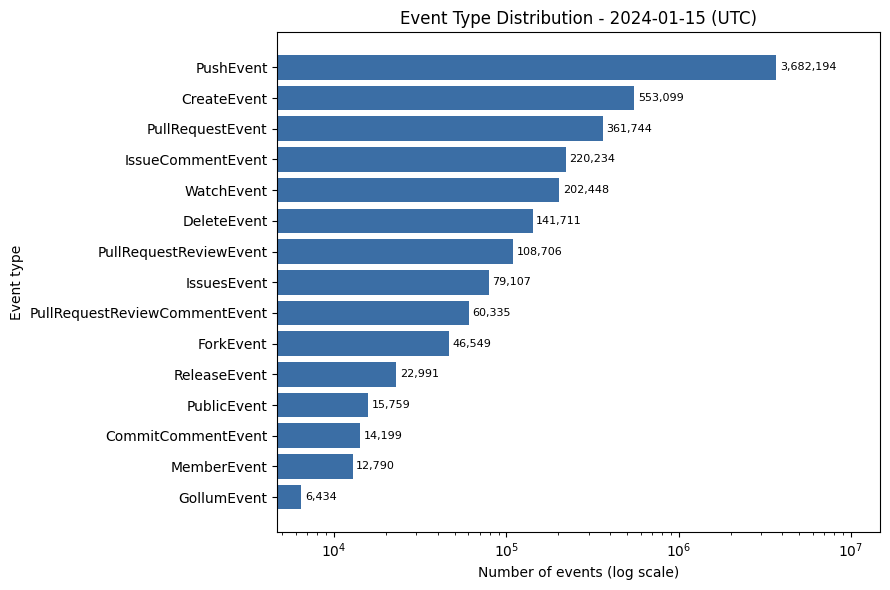

In [8]:
# Chart 1: event type distribution.
counts = type_counts["event_count"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.set_xscale("log")
ax.set_xlabel("Number of events (log scale)")
ax.set_ylabel("Event type")
ax.set_title("Event Type Distribution - 2024-01-15 (UTC)")
for bar, value in zip(bars, counts.values):
    ax.text(value * 1.05, bar.get_y() + bar.get_height() / 2,
            f"{value:,}", va="center", fontsize=8)
ax.set_xlim(right=counts.max() * 4)
fig.tight_layout()
fig.savefig(FIG_DIR / "event_type_distribution.png", dpi=150)
plt.show()

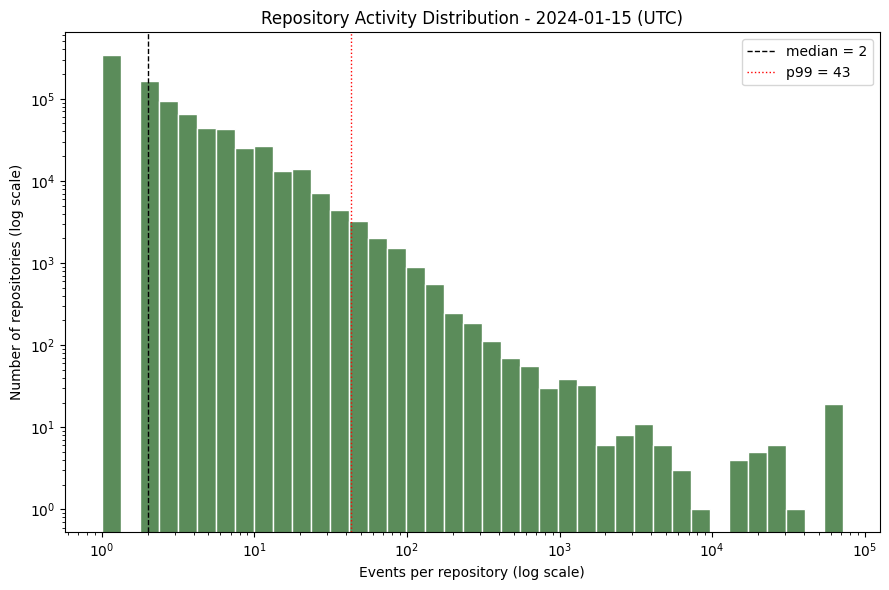

In [9]:
# Chart 2: repository activity distribution (events per repository).
fig, ax = plt.subplots(figsize=(9, 6))
bins = np.logspace(0, np.log10(repo_totals.max()) + 0.1, 40)
ax.hist(repo_totals.values, bins=bins, color="#5b8c5a", edgecolor="white")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Events per repository (log scale)")
ax.set_ylabel("Number of repositories (log scale)")
ax.set_title("Repository Activity Distribution - 2024-01-15 (UTC)")
median = repo_totals.median()
p99 = repo_totals.quantile(0.99)
ax.axvline(median, color="black", linestyle="--", linewidth=1, label=f"median = {median:g}")
ax.axvline(p99, color="red", linestyle=":", linewidth=1, label=f"p99 = {p99:g}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "repository_activity_distribution.png", dpi=150)
plt.show()

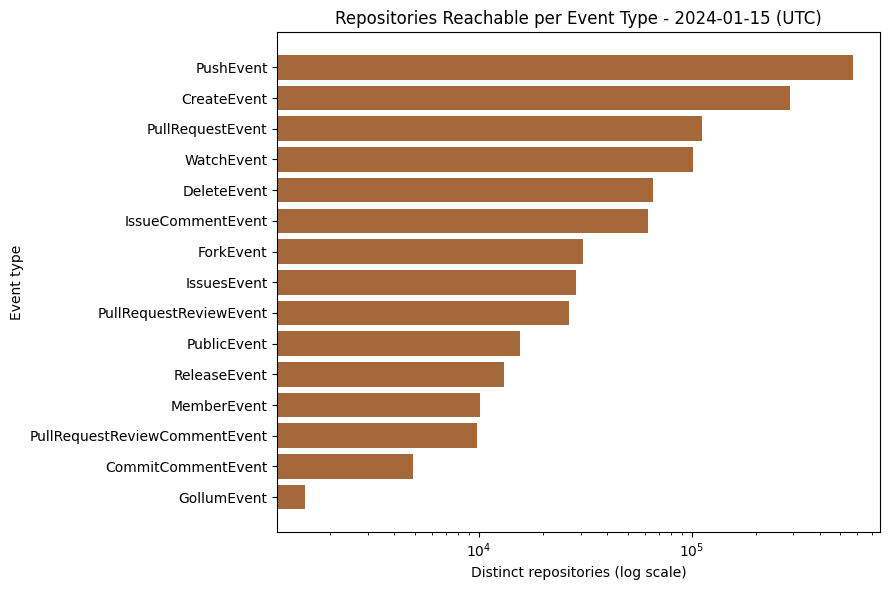

In [10]:
# Chart 3 (supplementary): breadth of each event type - how many repositories it touches.
breadth = type_counts["repo_count"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(breadth.index, breadth.values, color="#a5683b")
ax.set_xscale("log")
ax.set_xlabel("Distinct repositories (log scale)")
ax.set_ylabel("Event type")
ax.set_title("Repositories Reachable per Event Type - 2024-01-15 (UTC)")
fig.tight_layout()
fig.savefig(FIG_DIR / "event_type_repo_breadth.png", dpi=150)
plt.show()

### Reading the charts

- PushEvent dominates the event count (about 67% of the day) but is concentrated in relatively few
  repositories; WatchEvent and ForkEvent are smaller in volume yet spread across many repositories.
- The repository activity distribution is strongly skewed: most repositories produce only one event in a
  day, while a small number produce hundreds. This is why a mean alone is misleading; use median and
  percentiles, and prefer defining activity on a log scale.
- These patterns are shown for a single UTC day. They describe what is happening on 2024-01-15, not how
  repositories evolve over their lifetime.

## 7. Lifecycle metric definitions

Each metric is computed per repository. Two different units are kept apart on purpose: **event counts**
(how many activities) and **active days** (on how many distinct days an activity was observed).

| Metric | Unit | Definition | Source fields |
|---|---|---|---|
| `total_events` | events | sum of `event_count` for the repository | daily counts or event table |
| `push_events` | events | sum of `event_count` where `event_type == PushEvent` | |
| `issue_events` | events | sum of `IssuesEvent` and `IssueCommentEvent` | |
| `pr_events` | events | sum of `PullRequestEvent`, `PullRequestReviewEvent`, `PullRequestReviewCommentEvent` | |
| `active_days` | days | number of distinct `event_date` values with activity | daily counts `event_date` |

Notes and limits:

- The Issue and PR groupings are a **convention**. If the group decides to count only opened/closed issues,
  or to drop review events, change the type lists below and re-run. The choice must be stated in the report.
- One `PushEvent` is not one commit. A single push can carry several commits in its payload; counting commits
  would require the payload, which is not in the current event table.
- `active_days` needs a date column. On the current single-day table it is 1 for every repository. It only
  becomes informative once the observation window spans several days or months.

In [11]:
ISSUE_TYPES = ["IssuesEvent", "IssueCommentEvent"]
PR_TYPES = ["PullRequestEvent", "PullRequestReviewEvent", "PullRequestReviewCommentEvent"]


def repo_metrics(daily: pd.DataFrame) -> pd.DataFrame:
    """Compute per-repository activity metrics from a repo x date x type table.

    Expects columns: repo_id, event_date, event_type, event_count.
    """
    required = {"repo_id", "event_date", "event_type", "event_count"}
    missing = required - set(daily.columns)
    if missing:
        raise ValueError(f"missing columns: {sorted(missing)}")

    by_type = (
        daily.pivot_table(index="repo_id", columns="event_type",
                          values="event_count", aggfunc="sum", fill_value=0)
    )

    def sum_types(types):
        cols = [c for c in types if c in by_type.columns]
        return by_type[cols].sum(axis=1) if cols else 0

    metrics = pd.DataFrame(index=by_type.index)
    metrics["total_events"] = by_type.sum(axis=1)
    metrics["push_events"] = by_type.get("PushEvent", 0)
    metrics["issue_events"] = sum_types(ISSUE_TYPES)
    metrics["pr_events"] = sum_types(PR_TYPES)
    metrics["active_days"] = daily.groupby("repo_id")["event_date"].nunique()
    return metrics.sort_index()


repo_metrics_24h = repo_metrics(daily_24h)
print("repositories:", len(repo_metrics_24h))
repo_metrics_24h.head()

repositories: 852777


,total_events,push_events,issue_events,pr_events,active_days
repo_id,,,,,
130,17,6,0,5,1
140,2,0,0,0,1
144,1,0,0,0,1
363,7,0,3,4,1
507,1,0,0,0,1


In [12]:
# Sanity check: the metrics reconcile with the raw table.
assert repo_metrics_24h["total_events"].sum() == daily_24h["event_count"].sum()
print("total_events sum matches daily table:", int(repo_metrics_24h["total_events"].sum()))
print("active_days value counts (full day has a single date):")
print(repo_metrics_24h["active_days"].value_counts())

total_events sum matches daily table: 5528300
active_days value counts (full day has a single date):
active_days
1    852777
Name: count, dtype: int64


## 8. Reserved join with repository metadata (AI labels and creation time)

B owns the repository metadata and AI labels. The interface is a single key, `repo_id`. Only the 50
pilot repositories are available now; the same joins will run unchanged on B's full table once it is
delivered.

Two things to remember:

- `repo_created_at` from the API is the real repository creation time (used later for age months),
  while `first_observed_at` in `repo_candidates.csv` is only the first activity seen in the sample.
- `api_repo_id` must equal `repo_id` before the metadata is used; otherwise the row is a renamed or
  different repository and its metadata should be ignored.

In [13]:
# Keep only metadata rows whose API id matches the event-table repo id.
metadata_valid = metadata[metadata["api_repo_id"] == metadata["repo_id"]].copy()
print(f"metadata rows kept for the join: {len(metadata_valid)} / {len(metadata)}")

labels_slim = labels[["repo_id", "ai_label_auto", "ai_label_final", "label_source"]].drop_duplicates("repo_id")

repo_level = (
    repo_metrics_24h
    .reset_index()
    .merge(metadata_valid[["repo_id", "repo_created_at", "current_full_name", "language", "archived"]],
           on="repo_id", how="left")
    .merge(labels_slim, on="repo_id", how="left")
)

print("rows in repo-level table     :", len(repo_level))
print("rows matched to pilot metadata:", int(repo_level["repo_created_at"].notna().sum()))
repo_level[repo_level["repo_created_at"].notna()].head()

metadata rows kept for the join: 43 / 50


rows in repo-level table     : 852777
rows matched to pilot metadata: 43


,repo_id,total_events,push_events,issue_events,pr_events,active_days,repo_created_at,current_full_name,language,archived,ai_label_auto,ai_label_final,label_source
33278,82206054,43,14,7,17,1,2017-02-16T17:15:47Z,growilabs/growi,TypeScript,False,uncertain,excluded,manual_review
47878,125461135,1,0,0,0,1,2018-03-16T03:57:24Z,Dorothy-2016/panorama_slam,C++,False,excluded,excluded,auto_rule
108316,290350267,10,0,2,4,1,2020-08-25T23:59:48Z,chienhanlin/amazon-ecs-agent,Go,False,excluded,excluded,auto_rule
113096,302309533,1,1,0,0,1,2020-10-08T10:48:31Z,joaolucassilva/joaolucassilva,NaN,False,excluded,excluded,manual_review
114924,306977633,15,0,0,0,1,2020-10-24T21:49:40Z,AMAI-GmbH/AI-Expert-Roadmap,JavaScript,False,excluded,excluded,auto_rule


### Age-month placeholder

Lifecycle month is defined from the repository's own creation time, not from the calendar month:

- `age_month = 1` for the calendar month in which the repository was created,
- `age_month = 2` for the following month, and so on.

The function below computes the calendar-month difference. It can only be applied once the event window
covers more than one month, and only for repositories whose whole first 12 months fall inside the
observation window. It is defined here so the monthly analysis can reuse it directly.

In [14]:
def age_month(created_at, event_date):
    """Calendar-month age of an activity, 1-based from the creation month.

    Returns a Series aligned with event_date. Values <= 0 mean the activity predates
    the creation month (should not happen) and must be reviewed.
    """
    created = pd.to_datetime(created_at, utc=True).dt.tz_localize(None)
    occurred = pd.to_datetime(event_date)
    return ((occurred.dt.year - created.dt.year) * 12
            + (occurred.dt.month - created.dt.month) + 1)


# Demonstration on the pilot rows only (a single day, so every value is far from month 1 here).
demo = repo_level[repo_level["repo_created_at"].notna()].copy()
demo["age_month_on_2024_01_15"] = age_month(
    demo["repo_created_at"],
    pd.Series("2024-01-15", index=demo.index),
)
demo[["repo_id", "repo_created_at", "age_month_on_2024_01_15"]].head()

,repo_id,repo_created_at,age_month_on_2024_01_15
33278,82206054,2017-02-16T17:15:47Z,84
47878,125461135,2018-03-16T03:57:24Z,71
108316,290350267,2020-08-25T23:59:48Z,42
113096,302309533,2020-10-08T10:48:31Z,40
114924,306977633,2020-10-24T21:49:40Z,40


## 9. What is ready and what is pending

Ready now:

- Event type and repository activity statistics and charts on the 2024-01-15 sample.
- A reusable per-repository metric function and lifecycle metric definitions.
- The `repo_id` join between event data and repository metadata, verified on the 50 pilot rows.

Pending (blocks the monthly lifecycle analysis):

1. **`repo_created_at` for the full candidate list** - from B. Without it, age months cannot be computed
   for more than 50 repositories.
2. **AI labels for the full candidate list**, plus the final label policy (`manual_override` vs `auto_only`,
   and how `uncertain` is counted) - from B.
3. **A longer event window** - from A. A single day cannot show a repository's first year; the age-month
   table and the activity curves need several months of data.

Next work items once the inputs arrive:

1. Build the `repo_id x age_month` activity table and the monthly metric columns.
2. Plot activity against age month, separately for AI and non-AI repositories.
3. Compare early activity with month-12 activity, and only then consider grouping repositories into patterns.